# Team Members

|  **Student** |  **Name**     | **Entry Number** |
|:--------------:|:---------------:|:-------------------:|
| **1**          | ARPIT GOYAL     | 2023MT10202         |
| **2**          | HARSHAL LASOD   | 2023MT11076         |


---

# MTL782 - Assignment 2

Solutions for **Q1 (Dry Bean, UCI)** and **Q2 (MNIST)**.

- Classical classifiers: `scikit-learn`
- ANN: `PyTorch` (runs on GPU on Kaggle)
- Tuning: `GridSearchCV` + `RandomizedSearchCV`.


In [ ]:
# !pip install -q ucimlrepo


In [16]:
import warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from ucimlrepo import fetch_ucirepo
from sklearn.datasets import fetch_openml

from sklearn.model_selection import (train_test_split, GridSearchCV,
                                     RandomizedSearchCV, StratifiedKFold)
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             log_loss, roc_auc_score)
from sklearn.exceptions import ConvergenceWarning

from scipy.stats import randint, loguniform

warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', category=UserWarning)

pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 50)

SEED = 42
np.random.seed(SEED)


In [17]:
# pytorch (ANN will run on GPU if available)
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('torch device:', device)
if device == 'cuda':
    torch.backends.cudnn.benchmark = True
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)


torch device: cuda


## Helper - small PyTorch MLP

A reusable MLP + training loop so I don't repeat it for Q1 and Q2.


In [18]:
class MLP(nn.Module):
    def __init__(self, in_dim, hidden, out_dim, activation='relu', dropout=0.0):
        super().__init__()
        act = nn.ReLU if activation == 'relu' else nn.Tanh
        layers, prev = [], in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), act()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, out_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def train_mlp(Xtr, ytr, Xte, yte, in_dim, n_classes,
              hidden=(128, 64), activation='relu',
              lr=1e-3, weight_decay=1e-4, dropout=0.0,
              epochs=40, batch_size=128, verbose=True):
    # fit an MLP, return (model, y_pred, y_proba)
    model = MLP(in_dim, hidden, n_classes, activation, dropout).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss()

    Xtr_t = torch.tensor(np.asarray(Xtr), dtype=torch.float32)
    ytr_t = torch.tensor(np.asarray(ytr), dtype=torch.long)
    Xte_t = torch.tensor(np.asarray(Xte), dtype=torch.float32).to(device)

    loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=batch_size,
                        shuffle=True, pin_memory=(device == 'cuda'))

    bar = tqdm(range(epochs), desc='epochs', leave=False) if verbose else range(epochs)
    for _ in bar:
        model.train()
        total = 0.0
        for xb, yb in loader:
            xb = xb.to(device, non_blocking=True); yb = yb.to(device, non_blocking=True)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward(); opt.step()
            total += loss.item() * xb.size(0)
        if verbose:
            bar.set_postfix(loss=f'{total/len(Xtr_t):.4f}')

    model.eval()
    with torch.no_grad():
        logits = model(Xte_t)
        probs = torch.softmax(logits, dim=1).cpu().numpy()
        preds = probs.argmax(axis=1)
    return model, preds, probs


---
# Q1 - Dry Bean Dataset (UCI id = 602)

https://archive.ics.uci.edu/dataset/602/dry+bean+dataset


## Q1 (i) - Characterize the data

In [19]:
# fetch dataset
dry_bean = fetch_ucirepo(id=602)

X = dry_bean.data.features
y = dry_bean.data.targets
target_col = y.columns[0]

print(dry_bean.metadata)
print(dry_bean.variables)


{'uci_id': 602, 'name': 'Dry Bean', 'repository_url': 'https://archive.ics.uci.edu/dataset/602/dry+bean+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/602/data.csv', 'abstract': 'Images of 13,611 grains of 7 different registered dry beans were taken with a high-resolution camera. A total of 16 features; 12 dimensions and 4 shape forms, were obtained from the grains.', 'area': 'Biology', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 13611, 'num_features': 16, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': ['Class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2020, 'last_updated': 'Thu Mar 28 2024', 'dataset_doi': '10.24432/C50S4B', 'creators': [], 'intro_paper': {'ID': 244, 'type': 'NATIVE', 'title': 'Multiclass classification of dry beans using computer vision and machine learning techniques', 'authors': 'M. Koklu, Ilker Ali Özkan', 'venue': 'Co

In [20]:
print("number of classes:", y[target_col].nunique())

number of classes: 7


In [21]:
# data overview - one clean table per aspect

# 1. basic shapes + missing values
basics = pd.DataFrame(
    {'value': [X.shape, y.shape, int(X.isna().sum().sum()), int(y.isna().sum().sum())]},
    index=['X shape', 'y shape', 'missing in X', 'missing in y'],
)
print("--- Basic info ---")
print(basics.to_string())

# 2. class distribution
cls_dist = pd.DataFrame({
    'count'     : y[target_col].value_counts(),
    'proportion': y[target_col].value_counts(normalize=True).round(4),
})
print("\n--- Class distribution ---")
print(cls_dist.to_string())

# 3. feature summary
feat_summary = pd.DataFrame({
    'min' : X.min(),
    'max' : X.max(),
    'mean': X.mean().round(3),
    'std' : X.std().round(3),
    'missing': X.isna().sum(),
})
print("\n--- Feature summary ---")
print(feat_summary.to_string())


--- Basic info ---
                    value
X shape       (13611, 16)
y shape        (13611, 1)
missing in X            0
missing in y            0

--- Class distribution ---
          count  proportion
Class                      
DERMASON   3546      0.2605
SIRA       2636      0.1937
SEKER      2027      0.1489
HOROZ      1928      0.1417
CALI       1630      0.1198
BARBUNYA   1322      0.0971
BOMBAY      522      0.0384

--- Feature summary ---
                          min            max       mean        std  missing
Area             20420.000000  254616.000000  53048.285  29324.096        0
Perimeter          524.736000    1985.370000    855.283    214.290        0
MajorAxisLength    183.601165     738.860154    320.142     85.694        0
MinorAxisLength    122.512653     460.198497    202.271     44.970        0
AspectRatio          1.024868       2.430306      1.583      0.247        0
Eccentricity         0.218951       0.911423      0.751      0.092        0
ConvexArea    

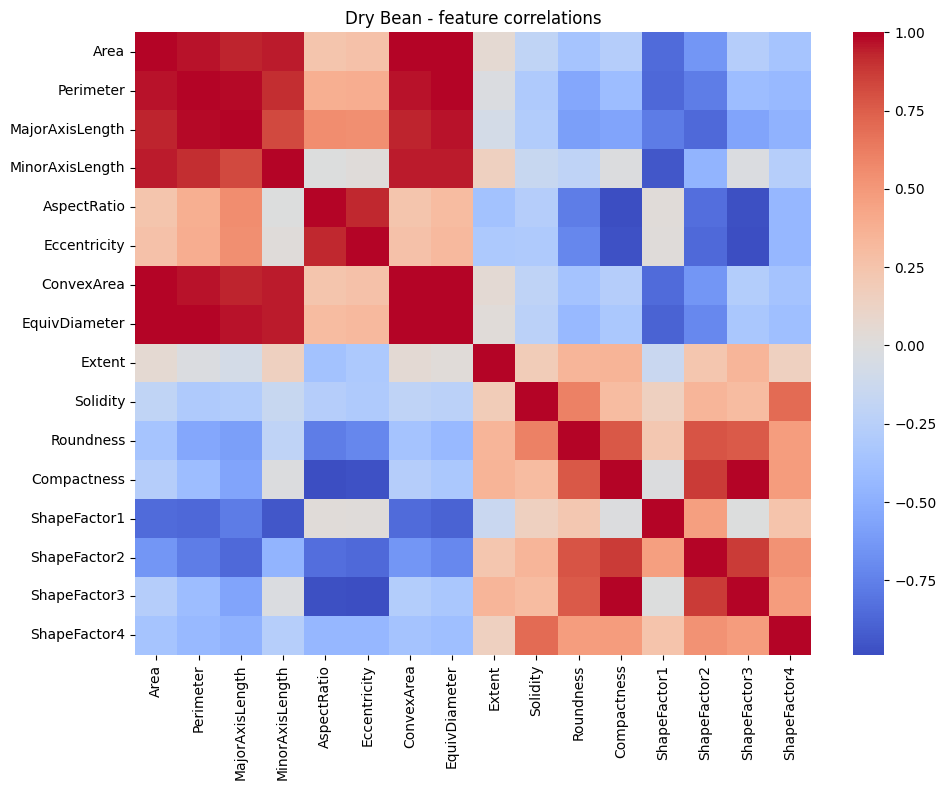

In [22]:
# correlation heatmap (for redundancy check)
plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(numeric_only=True), cmap='coolwarm', center=0)
plt.title('Dry Bean - feature correlations')
plt.tight_layout(); plt.show()


## 1) What the data is about

This is the Dry Bean Dataset from UCI. It contains morphological measurements of bean seeds and a class label identifying the bean variety.

- Inputs/features: shape and size measurements such as area, perimeter, axes lengths, compactness, roundness, etc.
- Target/output: bean type/class.

So, this is a supervised classification dataset.

---

## 2) What benefit data mining might provide

Data mining could help to:

- Automatically classify bean varieties from measurements.
- Reduce manual inspection in agriculture/food processing.
- Improve quality control by detecting unusual or misclassified beans.
- Identify the most important shape features that separate bean types.
- Build efficient sorting systems for production lines.

---

## 3) Data quality issues and response, by attribute

### Overall notes
- The dataset is mostly numerical.
- Likely no missing values in the standard UCI version.
- Main issues are usually:
  - different scales across attributes,
  - strong correlation/redundancy between shape variables,
  - outliers/skewness in some size measures,
  - class imbalance in the target.

### Attribute-by-attribute

| Attribute | Problems with the data? | Appropriate response |
|---|---|---|
| Area | May contain outliers; scale differs from other variables. | Standardize/normalize; inspect outliers. |
| Perimeter | Strongly correlated with Area and axis lengths. | Check multicollinearity; possibly use feature selection or PCA. |
| MajorAxisLength | May be skewed and correlated with other size features. | Scale the feature; inspect extreme values. |
| MinorAxisLength | Can be very small for elongated beans; correlation issues. | Standardize; check for anomalies. |
| AspectRation | Derived ratio; may be unstable if MinorAxisLength is small. | Verify formula consistency; consider transformation if skewed. |
| Eccentricity | Usually valid, but may be highly related to axis lengths. | Keep if useful, otherwise remove redundant features. |
| ConvexArea | Often highly correlated with Area; possible redundancy. | Test feature importance; remove if not helpful. |
| EquivDiameter | Derived from Area, so information may overlap heavily. | Keep only if model benefits; otherwise reduce redundancy. |
| Extent | Bounded measure; may have limited spread. | Check distribution; scaling may still help. |
| Solidity | Often narrow range; may be less informative alone. | Evaluate predictive value before keeping it. |
| Roundness | Derived shape measure; may be redundant with Compactness/Solidity. | Check correlation; use feature selection. |
| Compactness | Likely correlated with roundness and axis lengths. | Standardize and assess redundancy. |
| ShapeFactor1 | Derived feature; may duplicate information already in other variables. | Use correlation analysis; possibly drop if redundant. |
| ShapeFactor2 | Same issue as other shape factors: derivation and redundancy. | Evaluate importance and multicollinearity. |
| ShapeFactor3 | Derived from shape and size, likely correlated with other features. | Consider feature selection or dimensionality reduction. |
| ShapeFactor4 | Same as above; may add little independent information. | Keep only if it improves validation performance. |
| Class | Possible class imbalance across bean types. | Use stratified splits, class weights, or resampling if needed. |

---

## Summary

The dataset is generally clean and well-structured, but the main quality concerns are:

- feature redundancy
- different numeric scales
- possible outliers
- class imbalance

A good response would be:

- standardize features
- check correlation
- remove redundant variables if needed
- use stratified train/test split
- evaluate class-balanced models


## Q1 (ii) - 5 classifiers + k-fold CV + tuning

Models: Decision Tree, Random Forest, Naive Bayes, KNN, ANN (PyTorch).  
Tuning: `GridSearchCV`, 5-fold stratified, scored on `f1_macro` (classes are imbalanced).  
The PyTorch ANN uses a hand-rolled grid with `tqdm`.


In [23]:
# shared 80/20 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y[target_col], test_size=0.20,
    stratify=y[target_col], random_state=SEED,
)

# scaled copies for KNN / NB / ANN
sc = StandardScaler()
X_train_s = pd.DataFrame(sc.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_s  = pd.DataFrame(sc.transform(X_test),      columns=X_test.columns,  index=X_test.index)

print("train:", X_train.shape, " test:", X_test.shape)


train: (10888, 16)  test: (2723, 16)


In [24]:
# small helper - runs a fitted (Grid/Randomized)SearchCV and prints results nicely
def report_search(search, Xtr, ytr, Xte, yte, name):
    search.fit(Xtr, ytr)
    best = search.best_estimator_
    yp   = best.predict(Xte)

    acc = accuracy_score(yte, yp)
    f1m = f1_score(yte, yp, average='macro')

    summary = pd.DataFrame({
        'value': [search.best_params_, round(search.best_score_, 4),
                  round(acc, 4), round(f1m, 4)],
    }, index=['best params', 'best CV f1_macro', 'test accuracy', 'test f1_macro'])
    print(f'=== {name} ===')
    print(summary.to_string())
    print('\n' + classification_report(yte, yp))

    cm = confusion_matrix(yte, yp, labels=best.classes_)
    fig, ax = plt.subplots(figsize=(8, 6))
    ConfusionMatrixDisplay(cm, display_labels=best.classes_).plot(
        ax=ax, cmap='Blues', xticks_rotation=45, values_format='d', colorbar=False)
    plt.title(f'{name} - confusion matrix'); plt.tight_layout(); plt.show()

    return {'name': name, 'best': best, 'params': search.best_params_,
            'cv_score': search.best_score_, 'acc': acc, 'f1_macro': f1m, 'cm': cm}


### (1) Decision Tree

Fitting 5 folds for each of 320 candidates, totalling 1600 fits
=== Decision Tree ===
                                                                                                                            value
best params       {'class_weight': None, 'criterion': 'entropy', 'max_depth': 15, 'min_samples_leaf': 5, 'min_samples_split': 20}
best CV f1_macro                                                                                                           0.9244
test accuracy                                                                                                              0.9041
test f1_macro                                                                                                               0.917

              precision    recall  f1-score   support

    BARBUNYA       0.88      0.88      0.88       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.90      0.92       326
    DERMASON       0.90      0.90      0.90   

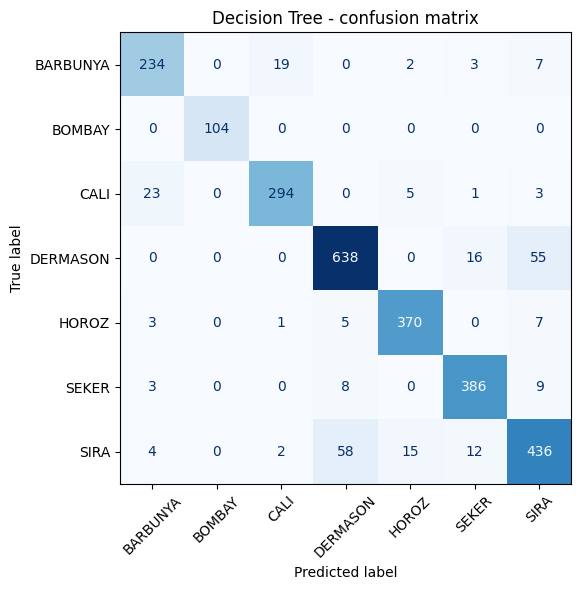

In [25]:
dt_grid = {
    'criterion'        : ['gini', 'entropy'],
    'max_depth'        : [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10, 20, 40],
    'min_samples_leaf' : [1, 5, 10, 20],
    'class_weight'     : [None, 'balanced'],
}

dt_search = GridSearchCV(
    DecisionTreeClassifier(random_state=SEED),
    dt_grid, cv=5, scoring='f1_macro', n_jobs=-1, verbose=1,
)

dt_result = report_search(dt_search, X_train, y_train, X_test, y_test, 'Decision Tree')


### (2) Random Forest

Fitting 5 folds for each of 64 candidates, totalling 320 fits
=== Random Forest ===
                                                                                                                     value
best params       {'class_weight': None, 'max_depth': 12, 'max_features': 0.6, 'min_samples_leaf': 4, 'n_estimators': 200}
best CV f1_macro                                                                                                    0.9372
test accuracy                                                                                                       0.9192
test f1_macro                                                                                                       0.9315

              precision    recall  f1-score   support

    BARBUNYA       0.94      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.93      0.93       326
    DERMASON       0.91      0.92      0.91       709
       HOROZ       0.97      

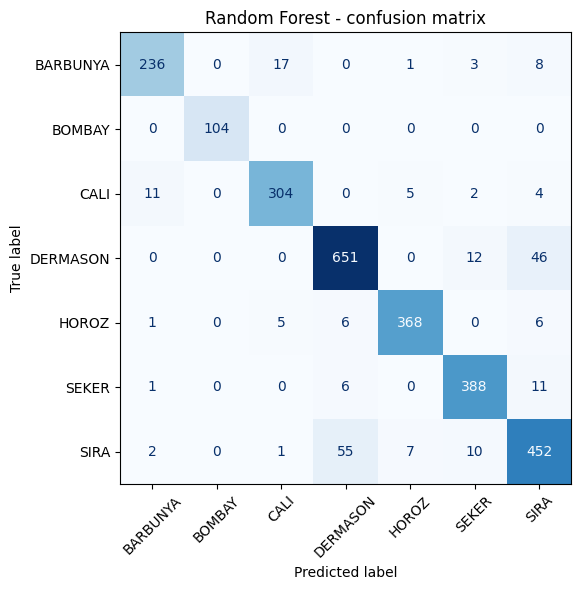

In [26]:
rf_grid = {
    'n_estimators'    : [200, 400],
    'max_depth'       : [8, 10, 12, None],
    'min_samples_leaf': [2, 4],
    'max_features'    : ['sqrt', 0.6],
    'class_weight'    : [None, 'balanced'],
}

rf_search = GridSearchCV(
    RandomForestClassifier(random_state=SEED, n_jobs=1),
    rf_grid, cv=5, scoring='f1_macro', n_jobs=-1, verbose=1,
)

rf_result = report_search(rf_search, X_train, y_train, X_test, y_test, 'Random Forest')


### (3) Naive Bayes (Gaussian)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
=== Naive Bayes ===
                                     value
best params       {'var_smoothing': 1e-10}
best CV f1_macro                    0.9062
test accuracy                       0.8979
test f1_macro                       0.9091

              precision    recall  f1-score   support

    BARBUNYA       0.90      0.80      0.85       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.86      0.92      0.89       326
    DERMASON       0.93      0.86      0.90       709
       HOROZ       0.95      0.95      0.95       386
       SEKER       0.92      0.94      0.93       406
        SIRA       0.81      0.89      0.84       527

    accuracy                           0.90      2723
   macro avg       0.91      0.91      0.91      2723
weighted avg       0.90      0.90      0.90      2723



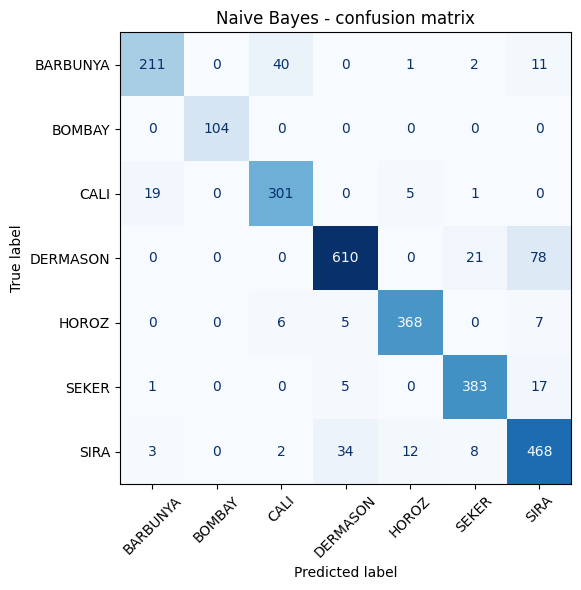

In [27]:
nb_grid = {'var_smoothing': [1e-10, 1e-9, 1e-8, 1e-7, 1e-6]}

nb_search = GridSearchCV(
    GaussianNB(), nb_grid,
    cv=5, scoring='f1_macro', n_jobs=-1, verbose=1,
)

nb_result = report_search(nb_search, X_train_s, y_train, X_test_s, y_test, 'Naive Bayes')


### (4) KNN

Fitting 5 folds for each of 20 candidates, totalling 100 fits
=== KNN ===
                                                                             value
best params       {'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'distance'}
best CV f1_macro                                                            0.9369
test accuracy                                                               0.9174
test f1_macro                                                                 0.93

              precision    recall  f1-score   support

    BARBUNYA       0.95      0.87      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.95      0.93       326
    DERMASON       0.91      0.91      0.91       709
       HOROZ       0.96      0.96      0.96       386
       SEKER       0.94      0.95      0.94       406
        SIRA       0.84      0.87      0.86       527

    accuracy                           0.92      2723
   macro avg       0.9

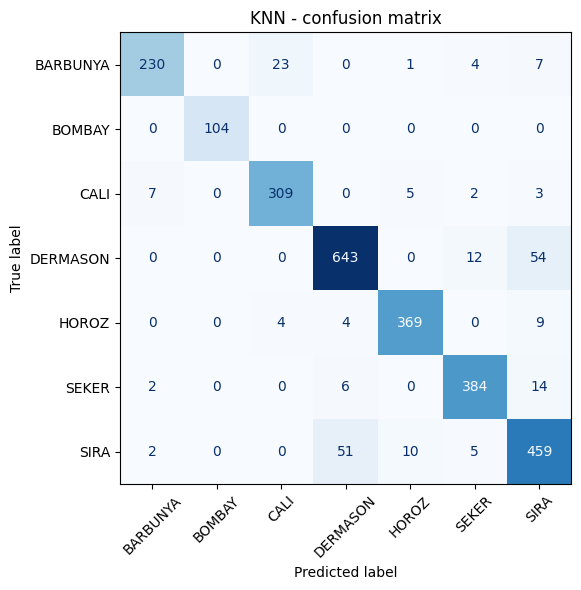

In [28]:
knn_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights'    : ['uniform', 'distance'],
    'metric'     : ['euclidean', 'manhattan'],
}

knn_search = GridSearchCV(
    KNeighborsClassifier(n_jobs=1), knn_grid,
    cv=5, scoring='f1_macro', n_jobs=-1, verbose=1,
)

knn_result = report_search(knn_search, X_train_s, y_train, X_test_s, y_test, 'KNN')


### (5) ANN

PyTorch doesn't plug into `GridSearchCV`, so I tune a few configs by hand on a held-out validation split.


In [29]:
# encode string labels -> int for PyTorch
le = LabelEncoder()
ytr_int = le.fit_transform(y_train)
yte_int = le.transform(y_test)
n_classes = len(le.classes_)

# validation split from training set
Xtr_in, Xva_in, ytr_in, yva_in = train_test_split(
    X_train_s.values, ytr_int, test_size=0.20,
    stratify=ytr_int, random_state=SEED,
)

ann_cfgs = [
    {'hidden': (64,),      'activation': 'relu', 'lr': 1e-3},
    {'hidden': (128,),     'activation': 'relu', 'lr': 1e-3},
    {'hidden': (128, 64),  'activation': 'relu', 'lr': 1e-3},
    {'hidden': (128, 64),  'activation': 'tanh', 'lr': 1e-3},
    {'hidden': (128, 64),  'activation': 'relu', 'lr': 1e-2},
    {'hidden': (256, 128), 'activation': 'relu', 'lr': 1e-3},
]

rows = []
for cfg in tqdm(ann_cfgs, desc='ANN configs'):
    _, yp_val, _ = train_mlp(Xtr_in, ytr_in, Xva_in, yva_in,
                             in_dim=Xtr_in.shape[1], n_classes=n_classes,
                             hidden=cfg['hidden'], activation=cfg['activation'],
                             lr=cfg['lr'], weight_decay=1e-4,
                             epochs=40, batch_size=128, verbose=False)
    rows.append({**cfg, 'val_f1_macro': round(f1_score(yva_in, yp_val, average='macro'), 4)})

ann_scan = pd.DataFrame(rows).sort_values('val_f1_macro', ascending=False).reset_index(drop=True)
print(ann_scan.to_string())

best_cfg = ann_scan.iloc[0][['hidden', 'activation', 'lr']].to_dict()
print('\nbest config:', best_cfg)


ANN configs:   0%|          | 0/6 [00:00<?, ?it/s]

       hidden activation     lr  val_f1_macro
0  (256, 128)       relu  0.001        0.9484
1      (128,)       relu  0.001        0.9473
2   (128, 64)       tanh  0.001        0.9461
3   (128, 64)       relu  0.001        0.9456
4       (64,)       relu  0.001        0.9418
5   (128, 64)       relu  0.010        0.9289

best config: {'hidden': (256, 128), 'activation': 'relu', 'lr': 0.001}


epochs:   0%|          | 0/60 [00:00<?, ?it/s]

=== ANN (PyTorch) ===
                                                                   value
best config    {'hidden': (256, 128), 'activation': 'relu', 'lr': 0.001}
test accuracy                                                     0.9277
test f1_macro                                                     0.9393

              precision    recall  f1-score   support

    BARBUNYA       0.93      0.92      0.93       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.95      0.94      0.94       326
    DERMASON       0.92      0.92      0.92       709
       HOROZ       0.97      0.96      0.96       386
       SEKER       0.95      0.95      0.95       406
        SIRA       0.87      0.88      0.87       527

    accuracy                           0.93      2723
   macro avg       0.94      0.94      0.94      2723
weighted avg       0.93      0.93      0.93      2723



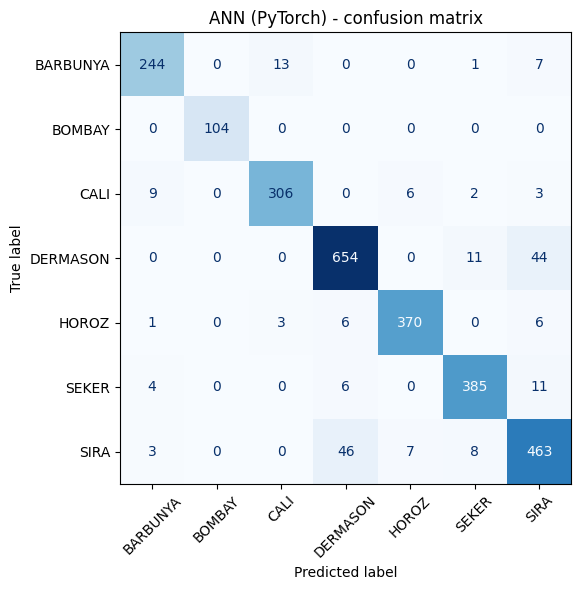

In [30]:
# retrain best ANN on full train, evaluate on test
ann_model, yp_ann_int, _ = train_mlp(
    X_train_s.values, ytr_int, X_test_s.values, yte_int,
    in_dim=X_train_s.shape[1], n_classes=n_classes,
    hidden=tuple(best_cfg['hidden']), activation=best_cfg['activation'],
    lr=float(best_cfg['lr']), weight_decay=1e-4,
    epochs=60, batch_size=128, verbose=True,
)
yp_ann = le.inverse_transform(yp_ann_int)

ann_acc = accuracy_score(y_test, yp_ann)
ann_f1m = f1_score(y_test, yp_ann, average='macro')

ann_summary = pd.DataFrame({
    'value': [best_cfg, round(ann_acc, 4), round(ann_f1m, 4)],
}, index=['best config', 'test accuracy', 'test f1_macro'])
print('=== ANN (PyTorch) ===')
print(ann_summary.to_string())
print('\n' + classification_report(y_test, yp_ann))

cm_ann = confusion_matrix(y_test, yp_ann, labels=le.classes_)
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(cm_ann, display_labels=le.classes_).plot(
    ax=ax, cmap='Blues', xticks_rotation=45, values_format='d', colorbar=False)
plt.title('ANN (PyTorch) - confusion matrix'); plt.tight_layout(); plt.show()

ann_result = {'name': 'ANN (PyTorch)', 'best': ann_model, 'params': best_cfg,
              'cv_score': ann_scan['val_f1_macro'].max(),
              'acc': ann_acc, 'f1_macro': ann_f1m, 'cm': cm_ann}


### Q1 comparison of all 5 classifiers

           model  cv_f1_macro  test_acc  test_f1_macro
0  ANN (PyTorch)       0.9484    0.9277         0.9393
1  Random Forest       0.9372    0.9192         0.9315
2            KNN       0.9369    0.9174         0.9300
3  Decision Tree       0.9244    0.9041         0.9170
4    Naive Bayes       0.9062    0.8979         0.9091


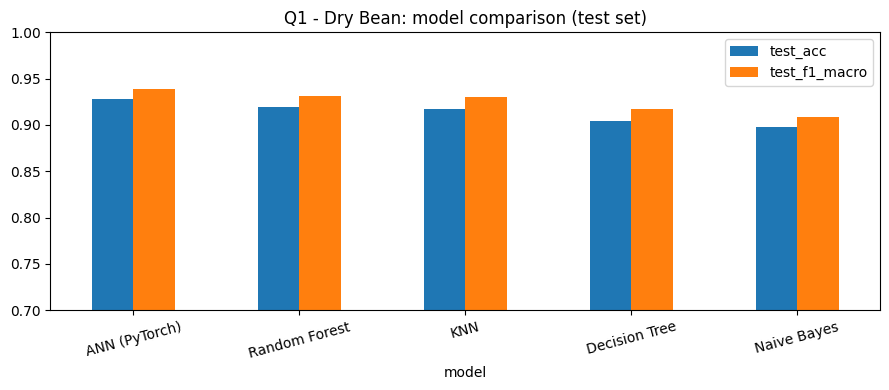

In [31]:
q1_results = [dt_result, rf_result, nb_result, knn_result, ann_result]
q1_df = pd.DataFrame([
    {'model'         : r['name'],
     'cv_f1_macro'   : round(r['cv_score'], 4),
     'test_acc'      : round(r['acc'], 4),
     'test_f1_macro' : round(r['f1_macro'], 4)}
    for r in q1_results
]).sort_values('test_f1_macro', ascending=False).reset_index(drop=True)

print(q1_df.to_string())

fig, ax = plt.subplots(figsize=(9, 4))
q1_df.set_index('model')[['test_acc', 'test_f1_macro']].plot.bar(ax=ax)
plt.ylim(0.7, 1.0)
plt.title('Q1 - Dry Bean: model comparison (test set)')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()


### Observations for Q1

| Rank | Model | CV F1-macro | Test acc | Test F1-macro |
|:-:|---|:-:|:-:|:-:|
| 1 | ANN (PyTorch) | 0.9484 | 0.9277 | 0.9393 |
| 2 | Random Forest | 0.9372 | 0.9192 | 0.9315 |
| 3 | KNN           | 0.9369 | 0.9174 | 0.9300 |
| 4 | Decision Tree | 0.9244 | 0.9041 | 0.9170 |
| 5 | Naive Bayes   | 0.9062 | 0.8979 | 0.9091 |

- All 5 models score > 90% — the 16 shape features separate bean varieties well.
- ANN wins; RF and KNN are effectively tied behind it.
- Naive Bayes is weakest — features like Area / Perimeter / ConvexArea are strongly correlated, so the independence assumption breaks.
- BOMBAY is perfectly classified (100%) for every model — it's a much larger bean.
- The hardest pair is SIRA vs DERMASON (similar medium size); every model scores lowest on SIRA (F1 ≈ 0.84–0.87).
- Scaling helped KNN / NB / ANN; CV vs test gap is ~1–2%, no major overfitting.


---
# Q2 - MNIST

Loaded through `sklearn.datasets.fetch_openml('mnist_784')`. Q2 (a)-(c) use a stratified 7 000-sample subset so that grid / randomized search finish in a sensible time; at the end we retrain the tuned models on the full MNIST (60k / 10k) for the final numbers.


## Q2 (a) - 5 classifiers on MNIST

In [ ]:
# load MNIST
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
X_mnist = mnist.data.astype(np.float32)
y_mnist = mnist.target.astype(np.int64)

print('full MNIST:', X_mnist.shape, '  labels:', sorted(np.unique(y_mnist)))


full MNIST: (70000, 784)   labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


In [33]:
SUBSET_N = 7000

# stratified subset
X_sub, _, y_sub, _ = train_test_split(
    X_mnist, y_mnist, train_size=SUBSET_N,
    stratify=y_mnist, random_state=SEED,
)

# 80/20 train/test on the subset
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(
    X_sub, y_sub, test_size=0.20,
    stratify=y_sub, random_state=SEED,
)

# scale (0-255 -> 0-mean / 1-std)
msc = StandardScaler()
Xm_tr_s = msc.fit_transform(Xm_tr)
Xm_te_s = msc.transform(Xm_te)

mnist_basics = pd.DataFrame({
    'value': [Xm_tr.shape, Xm_te.shape,
              dict(pd.Series(ym_tr).value_counts().sort_index()),
              dict(pd.Series(ym_te).value_counts().sort_index())]
}, index=['train shape', 'test shape',
          'train class counts', 'test class counts'])
print(mnist_basics.to_string())


                                                                                               value
train shape                                                                              (5600, 784)
test shape                                                                               (1400, 784)
train class counts  {0: 552, 1: 631, 2: 559, 3: 571, 4: 546, 5: 505, 6: 550, 7: 583, 8: 546, 9: 557}
test class counts   {0: 138, 1: 157, 2: 140, 3: 143, 4: 136, 5: 126, 6: 138, 7: 146, 8: 137, 9: 139}


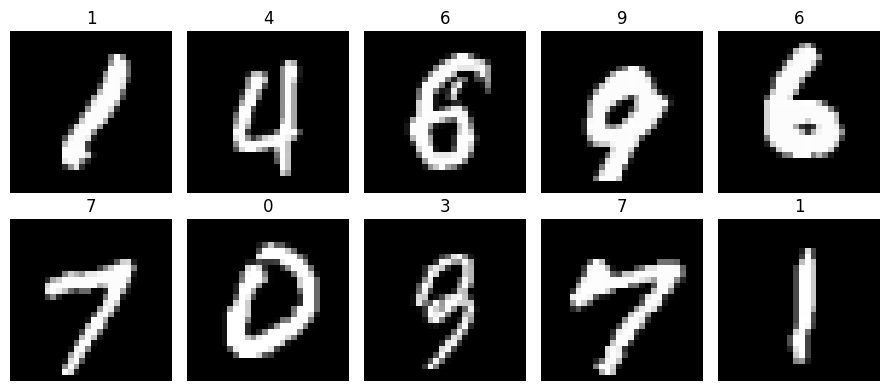

In [34]:
# peek at some digits
fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for ax, idx in zip(axes.ravel(), np.random.choice(len(Xm_tr), 10, replace=False)):
    ax.imshow(Xm_tr[idx].reshape(28, 28), cmap='gray')
    ax.set_title(str(ym_tr[idx])); ax.axis('off')
plt.tight_layout(); plt.show()


### (1) Decision Tree

In [35]:
dt_m = DecisionTreeClassifier(random_state=SEED, max_depth=15, min_samples_leaf=5)
dt_m.fit(Xm_tr, ym_tr)
ym_pred_dt = dt_m.predict(Xm_te)
print('DT  test acc :', round(accuracy_score(ym_te, ym_pred_dt), 4))


DT  test acc : 0.7886


### (2) Random Forest

In [36]:
rf_m = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED)
rf_m.fit(Xm_tr, ym_tr)
ym_pred_rf = rf_m.predict(Xm_te)
print('RF  test acc :', round(accuracy_score(ym_te, ym_pred_rf), 4))


RF  test acc : 0.945


### (3) Naive Bayes (Gaussian)

In [37]:
nb_m = GaussianNB()
nb_m.fit(Xm_tr_s, ym_tr)
ym_pred_nb = nb_m.predict(Xm_te_s)
print('NB  test acc :', round(accuracy_score(ym_te, ym_pred_nb), 4))


NB  test acc : 0.555


### (4) KNN

In [38]:
knn_m = KNeighborsClassifier(n_neighbors=3, weights='distance', n_jobs=-1)
knn_m.fit(Xm_tr_s, ym_tr)
ym_pred_knn = knn_m.predict(Xm_te_s)
print('KNN test acc :', round(accuracy_score(ym_te, ym_pred_knn), 4))


KNN test acc : 0.9021


### (5) ANN (PyTorch, GPU)

In [39]:
ann_m, ym_pred_ann, ym_prob_ann = train_mlp(
    Xm_tr_s, ym_tr, Xm_te_s, ym_te,
    in_dim=Xm_tr_s.shape[1], n_classes=10,
    hidden=(256, 128), activation='relu',
    lr=1e-3, weight_decay=1e-4, dropout=0.1,
    epochs=30, batch_size=128, verbose=True,
)
print('ANN test acc :', round(accuracy_score(ym_te, ym_pred_ann), 4))


epochs:   0%|          | 0/30 [00:00<?, ?it/s]

ANN test acc : 0.9343


## Q2 (b) - Evaluation Metrics

For every classifier I compute:

- Accuracy
- Precision / Recall / F1 (macro and weighted)
- Log-loss (needs class probabilities)
- ROC-AUC (one-vs-rest, macro)
- Per-class classification report
- Confusion matrix


In [40]:
classes = np.arange(10)
ym_te_bin = label_binarize(ym_te, classes=classes)

def safe_proba(model, X, pred):
    # returns a (n, 10) probability array, falls back to one-hot of the prediction
    try:
        p = np.asarray(model.predict_proba(X))
        if p.shape[1] == 10:
            return p
    except Exception:
        pass
    p = np.zeros((len(pred), 10), dtype=np.float32)
    p[np.arange(len(pred)), pred.astype(int)] = 1.0
    return p

mnist_models = {
    'Decision Tree' : (dt_m,  Xm_te,   ym_pred_dt,  safe_proba(dt_m,  Xm_te,   ym_pred_dt)),
    'Random Forest' : (rf_m,  Xm_te,   ym_pred_rf,  safe_proba(rf_m,  Xm_te,   ym_pred_rf)),
    'Naive Bayes'   : (nb_m,  Xm_te_s, ym_pred_nb,  safe_proba(nb_m,  Xm_te_s, ym_pred_nb)),
    'KNN'           : (knn_m, Xm_te_s, ym_pred_knn, safe_proba(knn_m, Xm_te_s, ym_pred_knn)),
    'ANN (PyTorch)' : (ann_m, Xm_te_s, ym_pred_ann, ym_prob_ann),
}


In [41]:
rows = []
for name, (model, Xte, yp, proba) in mnist_models.items():
    p = np.clip(proba, 1e-12, 1.0)
    p = p / p.sum(axis=1, keepdims=True)

    try:
        ll  = log_loss(ym_te, p, labels=classes)
    except Exception:
        ll = np.nan
    try:
        auc = roc_auc_score(ym_te_bin, p, average='macro', multi_class='ovr')
    except Exception:
        auc = np.nan

    rows.append({
        'model'          : name,
        'accuracy'       : accuracy_score(ym_te, yp),
        'precision_macro': precision_score(ym_te, yp, average='macro', zero_division=0),
        'recall_macro'   : recall_score(ym_te, yp, average='macro', zero_division=0),
        'f1_macro'       : f1_score(ym_te, yp, average='macro', zero_division=0),
        'f1_weighted'    : f1_score(ym_te, yp, average='weighted', zero_division=0),
        'log_loss'       : ll,
        'roc_auc_ovr'    : auc,
    })

metrics_df = pd.DataFrame(rows).sort_values('accuracy', ascending=False).reset_index(drop=True)
print(metrics_df.round(4).to_string())


           model  accuracy  precision_macro  recall_macro  f1_macro  f1_weighted  log_loss  roc_auc_ovr
0  Random Forest    0.9450           0.9454        0.9442    0.9445       0.9448    0.4403       0.9969
1  ANN (PyTorch)    0.9343           0.9341        0.9338    0.9334       0.9340    0.3191       0.9965
2            KNN    0.9021           0.9035        0.9009    0.9011       0.9016    1.3372       0.9820
3  Decision Tree    0.7886           0.7888        0.7861    0.7860       0.7875    4.2121       0.9319
4    Naive Bayes    0.5550           0.6179        0.5469    0.5085       0.5149   11.9330       0.7923


Decision Tree
              precision    recall  f1-score   support

           0     0.8741    0.8551    0.8645       138
           1     0.7872    0.9427    0.8580       157
           2     0.7687    0.7357    0.7518       140
           3     0.7000    0.6853    0.6926       143
           4     0.8682    0.8235    0.8453       136
           5     0.6963    0.7460    0.7203       126
           6     0.8467    0.8406    0.8436       138
           7     0.8581    0.8699    0.8639       146
           8     0.7931    0.6715    0.7273       137
           9     0.6957    0.6906    0.6931       139

    accuracy                         0.7886      1400
   macro avg     0.7888    0.7861    0.7860      1400
weighted avg     0.7894    0.7886    0.7875      1400



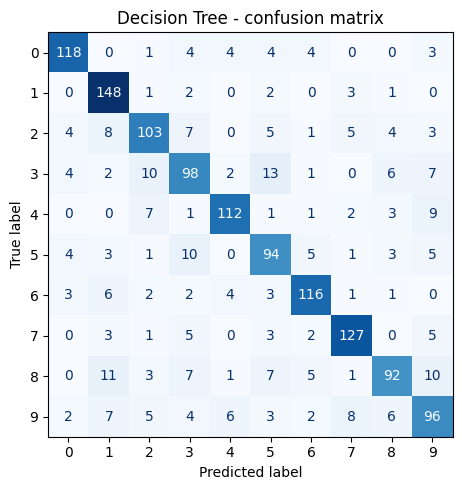

Random Forest
              precision    recall  f1-score   support

           0     0.9927    0.9855    0.9891       138
           1     0.9231    0.9936    0.9571       157
           2     0.9323    0.8857    0.9084       140
           3     0.9348    0.9021    0.9181       143
           4     0.9556    0.9485    0.9520       136
           5     0.9350    0.9127    0.9237       126
           6     0.9510    0.9855    0.9680       138
           7     0.9527    0.9658    0.9592       146
           8     0.9545    0.9197    0.9368       137
           9     0.9225    0.9424    0.9324       139

    accuracy                         0.9450      1400
   macro avg     0.9454    0.9442    0.9445      1400
weighted avg     0.9452    0.9450    0.9448      1400



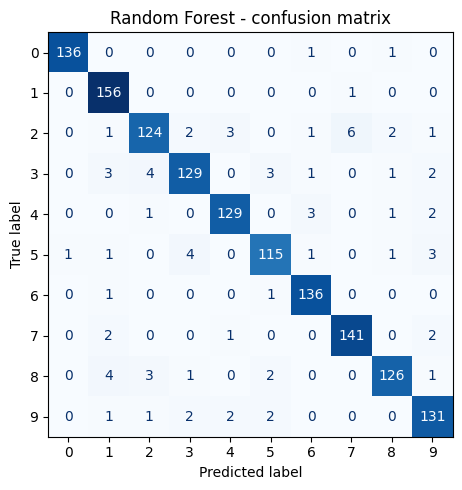

Naive Bayes
              precision    recall  f1-score   support

           0     0.6983    0.9058    0.7886       138
           1     0.6189    0.9618    0.7531       157
           2     0.8333    0.2857    0.4255       140
           3     0.7067    0.3706    0.4862       143
           4     0.7600    0.2794    0.4086       136
           5     0.3478    0.0635    0.1074       126
           6     0.6513    0.9203    0.7628       138
           7     0.8600    0.2945    0.4388       146
           8     0.3280    0.4453    0.3777       137
           9     0.3743    0.9424    0.5358       139

    accuracy                         0.5550      1400
   macro avg     0.6179    0.5469    0.5085      1400
weighted avg     0.6220    0.5550    0.5149      1400



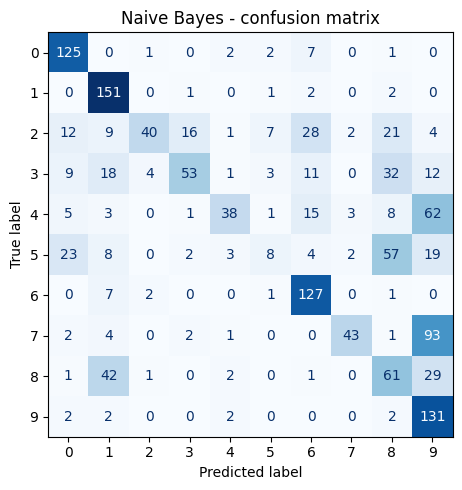

KNN
              precision    recall  f1-score   support

           0     0.9184    0.9783    0.9474       138
           1     0.8908    0.9873    0.9366       157
           2     0.9062    0.8286    0.8657       140
           3     0.8741    0.8741    0.8741       143
           4     0.9213    0.8603    0.8897       136
           5     0.8960    0.8889    0.8924       126
           6     0.9225    0.9493    0.9357       138
           7     0.9167    0.9041    0.9103       146
           8     0.9504    0.8394    0.8915       137
           9     0.8389    0.8993    0.8681       139

    accuracy                         0.9021      1400
   macro avg     0.9035    0.9009    0.9011      1400
weighted avg     0.9033    0.9021    0.9016      1400



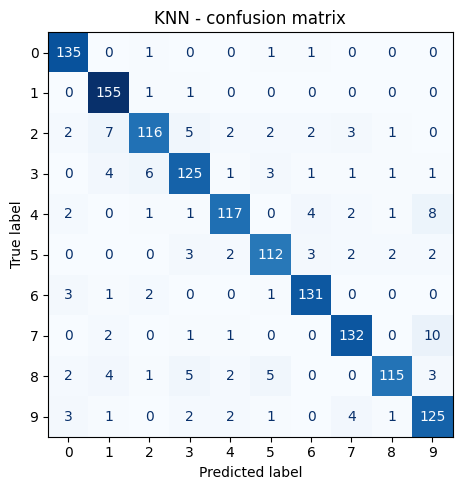

ANN (PyTorch)
              precision    recall  f1-score   support

           0     0.9716    0.9928    0.9821       138
           1     0.9630    0.9936    0.9781       157
           2     0.9242    0.8714    0.8971       140
           3     0.8836    0.9021    0.8927       143
           4     0.9412    0.9412    0.9412       136
           5     0.8759    0.9524    0.9125       126
           6     0.9437    0.9710    0.9571       138
           7     0.9384    0.9384    0.9384       146
           8     0.9375    0.8759    0.9057       137
           9     0.9615    0.8993    0.9294       139

    accuracy                         0.9343      1400
   macro avg     0.9341    0.9338    0.9334      1400
weighted avg     0.9348    0.9343    0.9340      1400



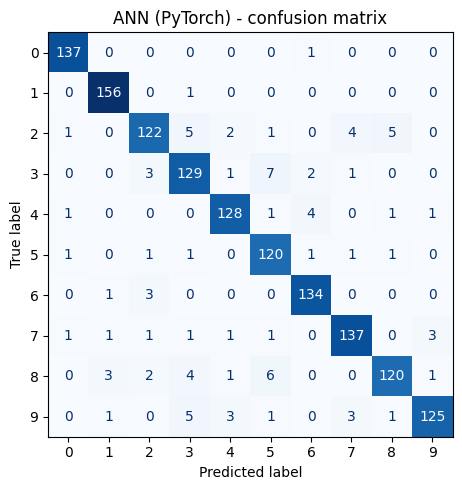

In [42]:
# per-model classification report + confusion matrix
for name, (model, Xte, yp, _) in mnist_models.items():
    print('=' * 60)
    print(name)
    print('=' * 60)
    print(classification_report(ym_te, yp, digits=4))

    cm = confusion_matrix(ym_te, yp, labels=classes)
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    plt.title(f'{name} - confusion matrix'); plt.tight_layout(); plt.show()


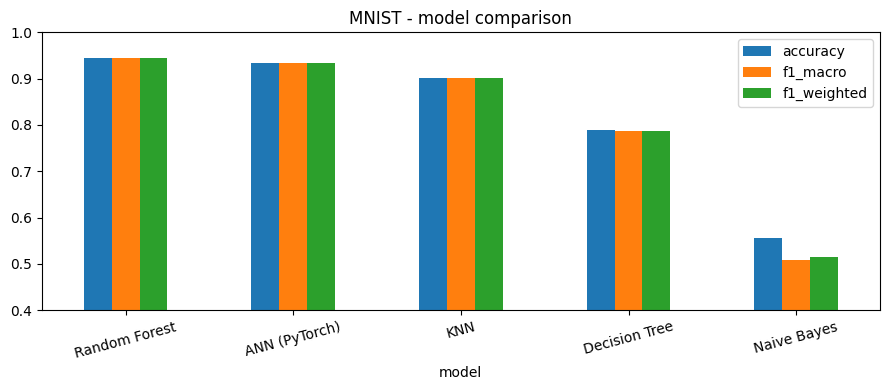

In [43]:
# side-by-side bar chart of the headline metrics
fig, ax = plt.subplots(figsize=(9, 4))
metrics_df.set_index('model')[['accuracy', 'f1_macro', 'f1_weighted']].plot.bar(ax=ax)
plt.ylim(0.4, 1.0)
plt.title('MNIST - model comparison')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()


### Observations for Q2 (b)

All metrics on the 7k-subset test set (1 400 images):

| Model | Acc | F1-macro | Log-loss | ROC-AUC (OvR) |
|---|:-:|:-:|:-:|:-:|
| Random Forest | 0.9450 | 0.9445 | 0.4403 | 0.9969 |
| ANN (PyTorch) | 0.9343 | 0.9334 | 0.3191 | 0.9965 |
| KNN           | 0.9021 | 0.9011 | 1.3372 | 0.9820 |
| Decision Tree | 0.7886 | 0.7860 | 4.2121 | 0.9319 |
| Naive Bayes   | 0.5550 | 0.5085 | 11.9330 | 0.7923 |

- Accuracy and F1 agree on the ranking; F1-macro ≈ F1-weighted because MNIST is balanced.
- Log-loss ranks differently: ANN < RF even though RF has higher accuracy → ANN's probabilities are better calibrated. KNN's vote-share "probabilities" are poorly calibrated (log-loss 1.34 despite 0.90 accuracy).
- ROC-AUC is near-perfect (0.997) for the top models but collapses to 0.79 for Naive Bayes.
- Naive Bayes fails on pixel data (not Gaussian, not independent). Decision Tree alone is also weak on 784-D input.
- Take-away: pick the metric for the use-case — accuracy hides calibration issues that log-loss exposes.


## Q2 (c) - Parameter Tuning: Grid Search and Randomized Search

Two standard tuning strategies:

- **`GridSearchCV`** - tries every combination in a discrete grid. Exhaustive, fine for small spaces.
- **`RandomizedSearchCV`** - samples `n_iter` random combinations from the given distributions. Much better when parameters are continuous.

Below:

- Grid search on **Random Forest**.
- Randomized search on **sklearn MLP** (with `loguniform` distributions).
- **Grid vs Randomized on KNN** - direct comparison on the same space.
- A **hand-written grid search on the PyTorch ANN (GPU)** with a `tqdm` progress bar.


### Grid Search - Random Forest

In [44]:
rf_grid_m = {
    'n_estimators'    : [100, 200, 400],
    'max_depth'       : [None, 15, 25],
    'min_samples_leaf': [1, 2],
    'max_features'    : ['sqrt', 'log2'],
}

rf_grid_search = GridSearchCV(
    RandomForestClassifier(random_state=SEED, n_jobs=1),
    rf_grid_m, cv=3, scoring='accuracy', n_jobs=-1, verbose=1,
)
rf_grid_search.fit(Xm_tr, ym_tr)

print(pd.DataFrame({
    'value': [rf_grid_search.best_params_,
              round(rf_grid_search.best_score_, 4),
              round(accuracy_score(ym_te, rf_grid_search.predict(Xm_te)), 4)],
}, index=['best params', 'best CV acc', 'test acc']).to_string())


Fitting 3 folds for each of 36 candidates, totalling 108 fits
                                                                                               value
best params  {'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 1, 'n_estimators': 400}
best CV acc                                                                                   0.9393
test acc                                                                                      0.9471


### Randomized Search - MLP (sklearn)

In [ ]:
mlp_dist = {
    'hidden_layer_sizes': [(64,), (128,), (128, 64), (256, 128)],
    'activation'        : ['relu', 'tanh'],
    'alpha'             : loguniform(1e-5, 1e-2),
    'learning_rate_init': loguniform(1e-4, 1e-2),
}

mlp_rand = RandomizedSearchCV(
    MLPClassifier(max_iter=30, random_state=SEED),
    mlp_dist, n_iter=15,
    cv=3, scoring='accuracy', n_jobs=-1, verbose=1, random_state=SEED,
)
mlp_rand.fit(Xm_tr_s, ym_tr)

print(pd.DataFrame({
    'value': [mlp_rand.best_params_,
              round(mlp_rand.best_score_, 4),
              round(accuracy_score(ym_te, mlp_rand.predict(Xm_te_s)), 4)],
}, index=['best params', 'best CV acc', 'test acc']).to_string())


### Grid vs Randomized - KNN (same-ish space)

In [46]:
knn_grid_m = {
    'n_neighbors': [1, 3, 5, 7, 9, 11, 15],
    'weights'    : ['uniform', 'distance'],
    'p'          : [1, 2],
}

knn_grid_s = GridSearchCV(KNeighborsClassifier(n_jobs=1), knn_grid_m,
                          cv=3, scoring='accuracy', n_jobs=-1, verbose=1)
knn_grid_s.fit(Xm_tr_s, ym_tr)

knn_dist = {
    'n_neighbors': randint(1, 20),
    'weights'    : ['uniform', 'distance'],
    'p'          : [1, 2],
}

knn_rand_s = RandomizedSearchCV(KNeighborsClassifier(n_jobs=1), knn_dist,
                                n_iter=10, cv=3, scoring='accuracy',
                                n_jobs=-1, verbose=1, random_state=SEED)
knn_rand_s.fit(Xm_tr_s, ym_tr)

knn_cmp = pd.DataFrame([
    {'method': 'Grid',       'best_params': knn_grid_s.best_params_,
     'cv_acc': round(knn_grid_s.best_score_, 4),
     'test_acc': round(accuracy_score(ym_te, knn_grid_s.predict(Xm_te_s)), 4)},
    {'method': 'Randomized', 'best_params': knn_rand_s.best_params_,
     'cv_acc': round(knn_rand_s.best_score_, 4),
     'test_acc': round(accuracy_score(ym_te, knn_rand_s.predict(Xm_te_s)), 4)},
])
print(knn_cmp.to_string(index=False))


Fitting 3 folds for each of 28 candidates, totalling 84 fits
Fitting 3 folds for each of 10 candidates, totalling 30 fits
    method                                        best_params  cv_acc  test_acc
      Grid  {'n_neighbors': 3, 'p': 1, 'weights': 'distance'}  0.9118    0.9271
Randomized {'n_neighbors': 11, 'p': 1, 'weights': 'distance'}  0.8993    0.9171


### Grid search on the PyTorch ANN (GPU)

PyTorch models don't plug into `GridSearchCV`, so I loop through configs and score each on a
held-out validation split. Progress shown with `tqdm`.


In [47]:
# inner validation split for the torch ANN
Xtr_in2, Xva_in2, ytr_in2, yva_in2 = train_test_split(
    Xm_tr_s, ym_tr, test_size=0.2, stratify=ym_tr, random_state=SEED,
)

torch_cfgs = [
    {'hidden': (128,),     'lr': 1e-3, 'dropout': 0.0},
    {'hidden': (256,),     'lr': 1e-3, 'dropout': 0.0},
    {'hidden': (256, 128), 'lr': 1e-3, 'dropout': 0.1},
    {'hidden': (256, 128), 'lr': 1e-3, 'dropout': 0.2},
    {'hidden': (512, 256), 'lr': 1e-3, 'dropout': 0.2},
    {'hidden': (256, 128), 'lr': 1e-2, 'dropout': 0.1},
]

rows = []
for cfg in tqdm(torch_cfgs, desc='torch-ANN grid'):
    _, yp_val, _ = train_mlp(
        Xtr_in2, ytr_in2, Xva_in2, yva_in2,
        in_dim=Xtr_in2.shape[1], n_classes=10,
        hidden=cfg['hidden'], activation='relu',
        lr=cfg['lr'], weight_decay=1e-4, dropout=cfg['dropout'],
        epochs=20, batch_size=128, verbose=False,
    )
    rows.append({**cfg, 'val_acc': round(accuracy_score(yva_in2, yp_val), 4)})

torch_scan = pd.DataFrame(rows).sort_values('val_acc', ascending=False).reset_index(drop=True)
print(torch_scan.to_string())

best_tcfg = torch_scan.iloc[0].to_dict()
print('\nbest torch-ANN config:', best_tcfg)


torch-ANN grid:   0%|          | 0/6 [00:00<?, ?it/s]

       hidden     lr  dropout  val_acc
0      (128,)  0.001      0.0   0.9464
1  (512, 256)  0.001      0.2   0.9464
2      (256,)  0.001      0.0   0.9429
3  (256, 128)  0.001      0.2   0.9429
4  (256, 128)  0.001      0.1   0.9420
5  (256, 128)  0.010      0.1   0.9250

best torch-ANN config: {'hidden': (128,), 'lr': 0.001, 'dropout': 0.0, 'val_acc': 0.9464}


In [48]:
# retrain best config on full train, evaluate on test
_, yp_ann_tuned, _ = train_mlp(
    Xm_tr_s, ym_tr, Xm_te_s, ym_te,
    in_dim=Xm_tr_s.shape[1], n_classes=10,
    hidden=tuple(best_tcfg['hidden']), activation='relu',
    lr=float(best_tcfg['lr']), weight_decay=1e-4,
    dropout=float(best_tcfg['dropout']),
    epochs=40, batch_size=128, verbose=True,
)
print('tuned torch-ANN test acc:', round(accuracy_score(ym_te, yp_ann_tuned), 4))


epochs:   0%|          | 0/40 [00:00<?, ?it/s]

tuned torch-ANN test acc: 0.9386


### Summary of tuned models

In [50]:
tuned_rows = [
    {'model': 'RF  (GridSearch)',
     'cv_acc': round(rf_grid_search.best_score_, 4),
     'test_acc': round(accuracy_score(ym_te, rf_grid_search.predict(Xm_te)), 4)},
    {'model': 'MLP (RandomizedSearch, sklearn)',
     'cv_acc': round(mlp_rand.best_score_, 4),
     'test_acc': round(accuracy_score(ym_te, mlp_rand.predict(Xm_te_s)), 4)},
    {'model': 'KNN (GridSearch)',
     'cv_acc': round(knn_grid_s.best_score_, 4),
     'test_acc': round(accuracy_score(ym_te, knn_grid_s.predict(Xm_te_s)), 4)},
    {'model': 'KNN (RandomizedSearch)',
     'cv_acc': round(knn_rand_s.best_score_, 4),
     'test_acc': round(accuracy_score(ym_te, knn_rand_s.predict(Xm_te_s)), 4)},
    {'model': 'ANN (manual grid, PyTorch GPU)',
     'cv_acc': round(float(torch_scan.iloc[0]['val_acc']), 4),
     'test_acc': round(accuracy_score(ym_te, yp_ann_tuned), 4)},
]
print(pd.DataFrame(tuned_rows).to_string(index=False))


                          model  cv_acc  test_acc
               RF  (GridSearch)  0.9393    0.9471
MLP (RandomizedSearch, sklearn)  0.9323    0.9379
               KNN (GridSearch)  0.9118    0.9271
         KNN (RandomizedSearch)  0.8993    0.9171
 ANN (manual grid, PyTorch GPU)  0.9464    0.9386


## Final training on full MNIST

We take the best hyperparameters from the tuning above and retrain the models on the full MNIST (60k train / 10k test) to see the real-data performance.


In [52]:
# canonical MNIST split (first 60k train, last 10k test)
Xf_tr, Xf_te = X_mnist[:60000], X_mnist[60000:]
yf_tr, yf_te = y_mnist[:60000], y_mnist[60000:]

# refit scaler on full train
sc_f = StandardScaler()
Xf_tr_s = sc_f.fit_transform(Xf_tr)
Xf_te_s = sc_f.transform(Xf_te)

print("train:", Xf_tr.shape, " test:", Xf_te.shape)

train: (60000, 784)  test: (10000, 784)


Decision Tree    acc=0.8812  (13.6s)
Random Forest    acc=0.9683  (29.2s)
Naive Bayes      acc=0.5240  (1.7s)
KNN              acc=0.9592  (715.1s)
MLP (sklearn)    acc=0.9756  (90.6s)


epochs:   0%|          | 0/40 [00:00<?, ?it/s]

ANN (PyTorch)    acc=0.9762  (66.0s)

=== Full MNIST - metrics ===
           model  accuracy  precision_macro  recall_macro  f1_macro  f1_weighted  log_loss  roc_auc_ovr  time_s
0  ANN (PyTorch)    0.9762           0.9764        0.9759    0.9761       0.9762    0.1114       0.9991    66.0
1  MLP (sklearn)    0.9756           0.9756        0.9754    0.9754       0.9756    0.1510       0.9991    90.6
2  Random Forest    0.9683           0.9682        0.9680    0.9681       0.9683    0.3055       0.9990    29.2
3            KNN    0.9592           0.9598        0.9587    0.9590       0.9591    0.5728       0.9917   715.1
4  Decision Tree    0.8812           0.8794        0.8795    0.8793       0.8810    2.0668       0.9446    13.6
5    Naive Bayes    0.5240           0.6698        0.5170    0.4692       0.4772   12.9294       0.7911     1.7
Decision Tree
              precision    recall  f1-score   support

           0     0.9059    0.9429    0.9240       980
           1     0.9572   

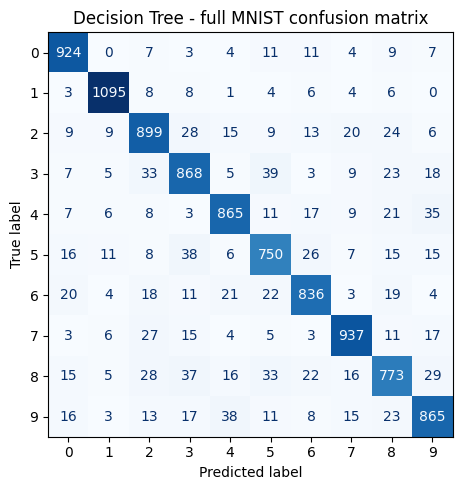

Random Forest
              precision    recall  f1-score   support

           0     0.9680    0.9888    0.9783       980
           1     0.9886    0.9903    0.9894      1135
           2     0.9660    0.9622    0.9641      1032
           3     0.9511    0.9624    0.9567      1010
           4     0.9724    0.9695    0.9709       982
           5     0.9783    0.9619    0.9700       892
           6     0.9731    0.9823    0.9777       958
           7     0.9725    0.9621    0.9672      1028
           8     0.9576    0.9507    0.9541       974
           9     0.9542    0.9504    0.9523      1009

    accuracy                         0.9683     10000
   macro avg     0.9682    0.9680    0.9681     10000
weighted avg     0.9683    0.9683    0.9683     10000



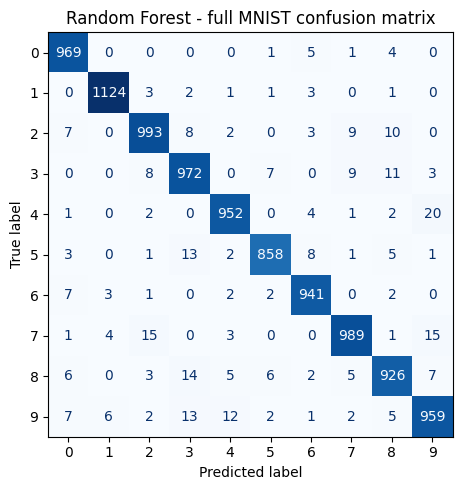

Naive Bayes
              precision    recall  f1-score   support

           0     0.7589    0.8449    0.7996       980
           1     0.8862    0.9401    0.9124      1135
           2     0.9010    0.1764    0.2950      1032
           3     0.6483    0.2792    0.3903      1010
           4     0.8600    0.1314    0.2279       982
           5     0.4531    0.0325    0.0607       892
           6     0.6938    0.9154    0.7894       958
           7     0.8816    0.1955    0.3201      1028
           8     0.2522    0.7023    0.3711       974
           9     0.3626    0.9524    0.5253      1009

    accuracy                         0.5240     10000
   macro avg     0.6698    0.5170    0.4692     10000
weighted avg     0.6765    0.5240    0.4772     10000



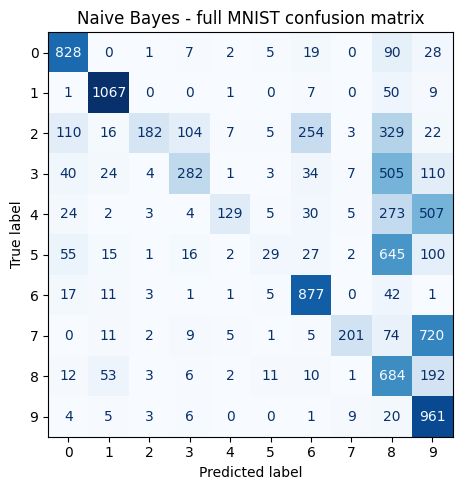

KNN
              precision    recall  f1-score   support

           0     0.9634    0.9939    0.9784       980
           1     0.9410    0.9982    0.9688      1135
           2     0.9790    0.9467    0.9626      1032
           3     0.9526    0.9554    0.9540      1010
           4     0.9718    0.9491    0.9603       982
           5     0.9457    0.9563    0.9509       892
           6     0.9802    0.9812    0.9807       958
           7     0.9413    0.9523    0.9468      1028
           8     0.9779    0.9097    0.9426       974
           9     0.9454    0.9445    0.9450      1009

    accuracy                         0.9592     10000
   macro avg     0.9598    0.9587    0.9590     10000
weighted avg     0.9596    0.9592    0.9591     10000



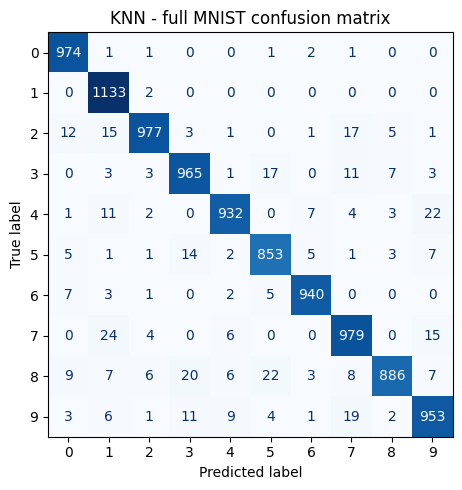

MLP (sklearn)
              precision    recall  f1-score   support

           0     0.9749    0.9898    0.9823       980
           1     0.9869    0.9938    0.9903      1135
           2     0.9745    0.9641    0.9693      1032
           3     0.9742    0.9723    0.9732      1010
           4     0.9629    0.9776    0.9702       982
           5     0.9808    0.9742    0.9775       892
           6     0.9894    0.9708    0.9800       958
           7     0.9738    0.9776    0.9757      1028
           8     0.9652    0.9682    0.9667       974
           9     0.9730    0.9653    0.9692      1009

    accuracy                         0.9756     10000
   macro avg     0.9756    0.9754    0.9754     10000
weighted avg     0.9756    0.9756    0.9756     10000



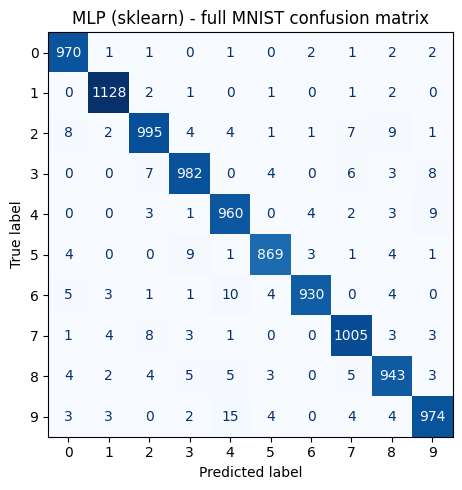

ANN (PyTorch)
              precision    recall  f1-score   support

           0     0.9847    0.9878    0.9862       980
           1     0.9825    0.9903    0.9864      1135
           2     0.9757    0.9709    0.9733      1032
           3     0.9519    0.9802    0.9659      1010
           4     0.9876    0.9756    0.9816       982
           5     0.9874    0.9641    0.9756       892
           6     0.9771    0.9802    0.9786       958
           7     0.9680    0.9718    0.9699      1028
           8     0.9782    0.9682    0.9732       974
           9     0.9712    0.9703    0.9707      1009

    accuracy                         0.9762     10000
   macro avg     0.9764    0.9759    0.9761     10000
weighted avg     0.9763    0.9762    0.9762     10000



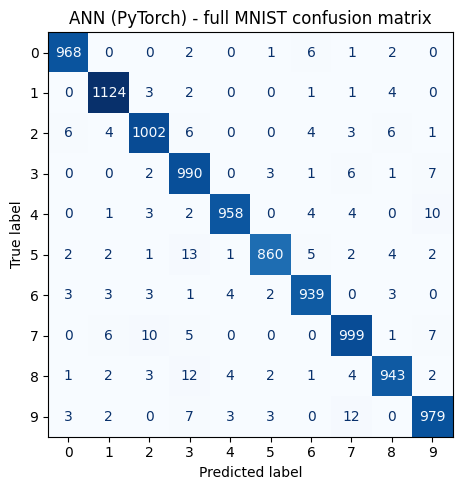

In [53]:
# retrain each tuned model on full MNIST and collect metrics
classes = np.arange(10)
yte_bin = label_binarize(yf_te, classes=classes)

rows, preds = [], {}

def evaluate(name, yp, proba, t):
    p = np.clip(proba, 1e-12, 1)
    p = p / p.sum(1, keepdims=True)
    rows.append({
        'model'          : name,
        'accuracy'       : accuracy_score(yf_te, yp),
        'precision_macro': precision_score(yf_te, yp, average='macro', zero_division=0),
        'recall_macro'   : recall_score(yf_te, yp, average='macro', zero_division=0),
        'f1_macro'       : f1_score(yf_te, yp, average='macro', zero_division=0),
        'f1_weighted'    : f1_score(yf_te, yp, average='weighted', zero_division=0),
        'log_loss'       : log_loss(yf_te, p, labels=classes),
        'roc_auc_ovr'    : roc_auc_score(yte_bin, p, average='macro', multi_class='ovr'),
        'time_s'         : round(t, 1),
    })
    preds[name] = yp
    print(f"{name:15s}  acc={rows[-1]['accuracy']:.4f}  ({rows[-1]['time_s']}s)")


# 1) decision tree
t0 = time.time()
m = DecisionTreeClassifier(random_state=SEED, max_depth=15, min_samples_leaf=5).fit(Xf_tr, yf_tr)
evaluate('Decision Tree', m.predict(Xf_te), m.predict_proba(Xf_te), time.time()-t0)

# 2) random forest (from grid search)
t0 = time.time()
m = RandomForestClassifier(**rf_grid_search.best_params_, random_state=SEED, n_jobs=-1).fit(Xf_tr, yf_tr)
evaluate('Random Forest', m.predict(Xf_te), m.predict_proba(Xf_te), time.time()-t0)

# 3) naive bayes
t0 = time.time()
m = GaussianNB().fit(Xf_tr_s, yf_tr)
evaluate('Naive Bayes', m.predict(Xf_te_s), m.predict_proba(Xf_te_s), time.time()-t0)

# 4) knn (from grid search)
t0 = time.time()
m = KNeighborsClassifier(**knn_grid_s.best_params_, n_jobs=-1).fit(Xf_tr_s, yf_tr)
evaluate('KNN', m.predict(Xf_te_s), m.predict_proba(Xf_te_s), time.time()-t0)

# 5) sklearn MLP (from random search, more iters this time)
t0 = time.time()
m = MLPClassifier(**mlp_rand.best_params_, max_iter=200, random_state=SEED).fit(Xf_tr_s, yf_tr)
evaluate('MLP (sklearn)', m.predict(Xf_te_s), m.predict_proba(Xf_te_s), time.time()-t0)

# 6) PyTorch ANN (from manual grid)
t0 = time.time()
_, yp, proba = train_mlp(
    Xf_tr_s, yf_tr, Xf_te_s, yf_te,
    in_dim=Xf_tr_s.shape[1], n_classes=10,
    hidden=tuple(best_tcfg['hidden']), activation='relu',
    lr=float(best_tcfg['lr']), weight_decay=1e-4,
    dropout=float(best_tcfg['dropout']),
    epochs=40, batch_size=256, verbose=True,
)
evaluate('ANN (PyTorch)', yp, proba, time.time()-t0)


# final metrics table
full_df = pd.DataFrame(rows).sort_values('accuracy', ascending=False).reset_index(drop=True)
print('\n=== Full MNIST - metrics ===')
print(full_df.round(4).to_string())


# per-model classification report + confusion matrix
for name, yp in preds.items():
    print('=' * 60); print(name); print('=' * 60)
    print(classification_report(yf_te, yp, digits=4))
    cm = confusion_matrix(yf_te, yp, labels=classes)
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    plt.title(f'{name} - full MNIST confusion matrix')
    plt.tight_layout(); plt.show()


### Observations for Q2 (c) and final training

Tuning (7k subset):

| Model | Search | Best CV | Test acc | Best config |
|---|---|:-:|:-:|---|
| RF           | Grid   | 0.9393 | 0.9471 | n_est=400, depth=None, max_feat=log2 |
| ANN (torch)  | Manual | 0.9464 | 0.9386 | hidden=(128,), lr=1e-3, dropout=0 |
| MLP sklearn  | Random | 0.9323 | 0.9379 | hidden=(256,128), α≈1e-3, lr≈1e-3 |
| KNN          | Grid   | 0.9118 | 0.9271 | k=3, p=1, weights=distance |
| KNN          | Random | 0.8993 | 0.9171 | k=11, p=1, weights=distance |

- Grid vs Randomized: Grid wins on KNN (small / discrete space). Randomized search on MLP landed at a near-top config in only 15 iterations — clearly the right tool for continuous parameters.
- RF, MLP and ANN were already near their ceiling with sensible defaults; tuning gave modest gains (+0.2 to +2.5%) on the subset.

Final training — full MNIST (60k train / 10k test):

| Rank | Model | Accuracy | F1-macro | Log-loss | ROC-AUC | Fit time |
|:-:|---|:-:|:-:|:-:|:-:|:-:|
| 1 | ANN (PyTorch) | 0.9762 | 0.9761 | 0.1114 | 0.9991 | 66 s |
| 2 | MLP (sklearn) | 0.9756 | 0.9754 | 0.1510 | 0.9991 | 91 s |
| 3 | Random Forest | 0.9683 | 0.9681 | 0.3055 | 0.9990 | 29 s |
| 4 | KNN           | 0.9592 | 0.9590 | 0.5728 | 0.9917 | 715 s |
| 5 | Decision Tree | 0.8812 | 0.8793 | 2.0668 | 0.9446 | 14 s |
| 6 | Naive Bayes   | 0.5240 | 0.4692 | 12.9294 | 0.7911 | 2 s |

Subset vs full-MNIST accuracy:

| Model | Subset (tuned, 1.4k test) | Full (10k test) | Δ |
|---|:-:|:-:|:-:|
| ANN (PyTorch) | 0.9386 | 0.9762 | +0.038 |
| MLP (sklearn) | 0.9379 | 0.9756 | +0.038 |
| Random Forest | 0.9471 | 0.9683 | +0.021 |
| KNN           | 0.9271 | 0.9592 | +0.032 |
| Decision Tree | 0.7886 | 0.8812 | +0.093 |
| Naive Bayes   | 0.5550 | 0.5240 | -0.031 |

- The two neural nets (PyTorch ANN, sklearn MLP) tie at ~97.6% — highest in the notebook.
- Random Forest is the best speed / accuracy trade-off — 96.8% in just 29 s.
- KNN improved (to 95.9%) but was by far the slowest — 715 s (most of it is test-time distance computation on 60k train points).
- Decision Tree gained the most from extra data (+9.3 pts) but still trails the top models by ~9%.
- Naive Bayes got worse with more data — confirming that more samples can't fix a wrong model assumption.


---
## Final remarks

Winning models:

| Task | Best model | Test accuracy |
|---|---|:-:|
| Q1 — Dry Bean    | ANN (PyTorch) | 92.77 % (F1-macro 0.9393) |
| Q2 — MNIST (full)| ANN (PyTorch) | 97.62 % (F1-macro 0.9761) |

Key takeaways:

1. ANN is the most consistent performer on both tabular (Q1) and pixel (Q2) data.
2. Random Forest is the best practical choice when compute matters — fast to train, strong accuracy, minimal tuning.
3. Naive Bayes struggles whenever features are correlated / non-Gaussian. More data doesn't help (Q2: 0.555 → 0.524).
4. Decision Tree alone is too weak on high-dimensional data; ensembles (RF) fix it.
5. Preprocessing matters: scaling for KNN / NB / ANN, stratified splits for imbalanced classes (Q1).
6. Tuning strategy: GridSearch for small / discrete spaces, RandomizedSearch for continuous / large spaces. Gains ranged from ~0.2 % (RF) to ~2.5 % (KNN) on the subset.
7. Metrics beyond accuracy (log-loss, ROC-AUC) expose calibration and ranking quality — ANN consistently had the best-calibrated probabilities.
